# 05 – WVS Feature Experiments

## Research Purpose

This notebook investigates how imputation methods and feature selection influence the prediction of life satisfaction using World Values Survey (WVS) Wave 7 data.

The main objective is to identify a suitable feature configuration and imputation strategy before conducting the final model evaluation.

## Experimental Workflow

The notebook follows these steps:

1. **Data Preparation** – Load the cleaned training and test datasets, separate predictors and target, and prepare feature metadata.

2. **Imputation Methods** – Implement and compare Simple Imputation and Hierarchical Imputation.

3. **Feature Selection** – Identify the top 20 and top 30 predictors using Spearman correlation. Feature selection is performed within each training fold to prevent data leakage.

4. **Cross-Validation Setup** – Establish a fixed 5-Fold cross-validation procedure using identical data splits across experiments.

5. **Preprocessing** – Apply One-Hot Encoding to Country while retaining the selected survey variables.

6. **Model Evaluation** – Use Random Forest Regression to evaluate four experimental configurations:

   - Simple Imputation + Top 20 features
   - Simple Imputation + Top 30 features
   - Hierarchical Imputation + Top 20 features
   - Hierarchical Imputation + Top 30 features

7. **Performance Comparison** – Compare the configurations using R², MAE and RMSE, including variation across folds.

8. **Final Evaluation** – Select the preferred configuration based on cross-validation results and evaluate it once on the independent test set.

## Methodological Considerations

- Q49 (Life Satisfaction) is the prediction target and is excluded from all predictor sets.
- Country is retained as a categorical predictor but excluded from Spearman feature ranking.
- Imputation and feature selection are fitted independently within each cross-validation training fold.
- The final model is trained on the full training set and evaluated on the held-out test split.
- The same test split was used in earlier model comparisons in Notebook 06. Therefore, the final test metrics should not be interpreted as a completely untouched estimate of generalisation performance.
- Feature importance and predictive associations are not interpreted as causal effects.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy.stats import spearmanr

# Machine learning
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# File management
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Define project directories
PROJECT_DIR = Path.cwd().parent

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "modeling"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load processed datasets
train_df = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Train_Clean.csv"
)

test_df = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Test_Clean.csv"
)

feature_metadata = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Feature_Metadata.csv"
)

print("Data loaded successfully.")

Data loaded successfully.


In [3]:
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)
print("Feature metadata shape:", feature_metadata.shape)

print("\nTraining columns:")
print(train_df.columns[:10].tolist())

print("\nTarget distribution:")
print(train_df["Q49"].describe())

print("\nCountry count:")
print(train_df["Country"].nunique())

print("\nMissing target values:")
print(train_df["Q49"].isna().sum())

Training data shape: (77360, 244)
Test data shape: (19340, 244)
Feature metadata shape: (241, 18)

Training columns:
['Unnamed: 0', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9']

Target distribution:
count    77360.000000
mean         7.061543
std          2.241049
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64

Country count:
66

Missing target values:
0


In [4]:
# Remove saved DataFrame index columns
train_df = train_df.loc[
    :, ~train_df.columns.str.startswith("Unnamed:")
]

test_df = test_df.loc[
    :, ~test_df.columns.str.startswith("Unnamed:")
]

print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

Training data shape: (77360, 243)
Test data shape: (19340, 243)


In [5]:
# Separate target and predictors
TARGET = "Q49"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTarget included in X_train:", TARGET in X_train.columns)
print("Target included in X_test:", TARGET in X_test.columns)

X_train: (77360, 242)
y_train: (77360,)
X_test: (19340, 242)
y_test: (19340,)

Target included in X_train: False
Target included in X_test: False


## 6.2 Leakage-Free Feature Selection and Cross-Validation Workflow

The following workflow illustrates how feature selection and model evaluation
will be performed using 5-fold cross-validation.

```text
Training Data
     |
     v
5-Fold Cross-Validation
     |
     +---- Fold 1
     |       |
     |       v
     |   Training Fold
     |       |
     |       v
     |   Calculate Spearman Correlations
     |       |
     |       v
     |   Select Top 20 / Top 30 Features
     |       |
     |       v
     |   Imputation + Encoding + Model Training
     |       |
     |       v
     |   Validation Fold Evaluation
     |
     +---- Fold 2
     |
     +---- Fold 3
     |
     +---- Fold 4
     |
     +---- Fold 5
     |
     v
Compare Cross-Validation Performance

In [6]:
def select_top_features(X, y, k):
    """
    Select the top k predictors using Spearman correlation.

    Feature ranking is calculated using only the supplied
    training data.
    """

    correlations = {}

    for column in X.columns:

        # Exclude nominal Country from Spearman ranking
        if column == "Country":
            continue

        valid = X[column].notna() & y.notna()

        if valid.sum() < 30:
            correlations[column] = 0
            continue

        rho, _ = spearmanr(
            X.loc[valid, column],
            y.loc[valid]
        )

        correlations[column] = abs(rho) if np.isfinite(rho) else 0

    # Rank predictors by absolute Spearman correlation
    ranked_features = sorted(
        correlations,
        key=correlations.get,
        reverse=True
    )

    return ranked_features[:k]

In [7]:
top20_test = select_top_features(
    X_train,
    y_train,
    k=20
)

top30_test = select_top_features(
    X_train,
    y_train,
    k=30
)

print("Top 20:", top20_test)
print("\nTop 30:", top30_test)

print("\nTop 20 count:", len(top20_test))
print("Top 30 count:", len(top30_test))

Top 20: ['Q50', 'Q48', 'Q47', 'Q251', 'Q288', 'Q54', 'Q53', 'Q51', 'Q159', 'Q254', 'Q131', 'Q252', 'Q250', 'Q163', 'Q55', 'Q158', 'Q286', 'Q287', 'Q75', 'Q52']

Top 30: ['Q50', 'Q48', 'Q47', 'Q251', 'Q288', 'Q54', 'Q53', 'Q51', 'Q159', 'Q254', 'Q131', 'Q252', 'Q250', 'Q163', 'Q55', 'Q158', 'Q286', 'Q287', 'Q75', 'Q52', 'Q249', 'Q253', 'Q106', 'Q138', 'Q137', 'Q58', 'Q80', 'Q56', 'Q189', 'Q45']

Top 20 count: 20
Top 30 count: 30


In [8]:
# Inspect feature metadata
print("Metadata columns:")
print(feature_metadata.columns.tolist())

print("\nMeasurement types:")
print(feature_metadata["Measurement_type"].value_counts())

print("\nNumber of variables:")
print(feature_metadata["Variable"].nunique())

print("\nMissing measurement types:")
print(feature_metadata["Measurement_type"].isna().sum())

Metadata columns:
['Variable', 'Feature_group', 'Variable_role', 'Model_status', 'Category', 'Column number', 'Data type', 'Missing count (NaN)', 'Missing percentage (NaN)', 'Unique values (excluding NaN)', 'Candidate special-code count', 'Candidate special-code details', 'Example values', 'Preliminary category', 'Measurement_type', 'Countries_with_valid_responses', 'Country_coverage_percentage', 'Respondents_with_valid_responses']

Measurement types:
Measurement_type
Ordinal    188
Binary      26
Nominal     26
Numeric      1
Name: count, dtype: int64

Number of variables:
241

Missing measurement types:
0


In [9]:
# Prepare metadata for imputation

imputation_feature_info = feature_metadata[
    ["Variable", "Measurement_type"]
].copy()

# Exclude variables not present in X_train
imputation_feature_info = imputation_feature_info[
    imputation_feature_info["Variable"].isin(X_train.columns)
].copy()

print("Number of features:", len(imputation_feature_info))
print("\nMeasurement types:")
print(imputation_feature_info["Measurement_type"].value_counts())

print("\nQ288 included:",
      "Q288" in imputation_feature_info["Variable"].values)

print("Country included:",
      "Country" in X_train.columns)

Number of features: 241

Measurement types:
Measurement_type
Ordinal    188
Binary      26
Nominal     26
Numeric      1
Name: count, dtype: int64

Q288 included: True
Country included: True


In [10]:
def get_imputation_value(series, method):
    """
    Calculate an imputation value from non-missing observations.
    """
    values = series.dropna()

    if len(values) == 0:
        return np.nan

    if method == "median":
        median_value = values.median()
        observed_values = np.sort(values.unique())

        return observed_values[
            np.argmin(np.abs(observed_values - median_value))
        ]

    return values.mode().iloc[0]

# Simple imputation is retained for cross-validation experiments.
# The final model uses hierarchical imputation.
def fit_simple_imputer(X_train, feature_info):
    """
    Learn simple imputation values from training data only.
    """

    stats = {
        "q288_global": get_imputation_value(
            X_train["Q288"], "median"
        ),
        "q288_country": {},
        "global": {}
    }

    # Q288: country median, with global fallback
    for country, group in X_train.groupby("Country", observed=True):
        valid = group["Q288"].dropna()

        if len(valid) > 0:
            stats["q288_country"][country] = (
                get_imputation_value(valid, "median")
            )

    # Other features: global median or mode
    for _, row in feature_info.iterrows():
        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        measurement = row["Measurement_type"]

        method = (
            "median"
            if measurement in ["Numeric", "Ordinal"]
            else "mode"
        )

        stats["global"][feature] = get_imputation_value(
            X_train[feature], method
        )

    return stats


def apply_simple_imputer(X, stats, feature_info):
    """
    Apply fitted imputation values to a dataset.
    """

    X_result = X.copy()

    # Impute Q288 first
    missing_q288 = X_result["Q288"].isna()

    country_values = X_result.loc[
        missing_q288, "Country"
    ].map(stats["q288_country"])

    X_result.loc[missing_q288, "Q288"] = (
        country_values.fillna(stats["q288_global"])
    )

    # Impute remaining features
    for _, row in feature_info.iterrows():
        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        X_result[feature] = X_result[feature].fillna(
            stats["global"][feature]
        )

    return X_result

In [11]:
# Fit using training data only
simple_stats = fit_simple_imputer(
    X_train,
    imputation_feature_info
)

# Apply to training and test data
X_train_simple = apply_simple_imputer(
    X_train,
    simple_stats,
    imputation_feature_info
)

X_test_simple = apply_simple_imputer(
    X_test,
    simple_stats,
    imputation_feature_info
)

print("Training shape:", X_train_simple.shape)
print("Test shape:", X_test_simple.shape)

print("\nTraining missing values:",
      X_train_simple.isna().sum().sum())

print("Test missing values:",
      X_test_simple.isna().sum().sum())

print("\nOriginal training shape:", X_train.shape)
print("Imputed training shape:", X_train_simple.shape)

Training shape: (77360, 242)
Test shape: (19340, 242)

Training missing values: 0
Test missing values: 0

Original training shape: (77360, 242)
Imputed training shape: (77360, 242)


In [12]:
# Hierarchical Imputation

MIN_GROUP_SIZE = 30


def fit_hierarchical_imputer(
    X_train,
    feature_info,
    min_group_size=30
):
    """
    Learn hierarchical imputation values from training data only.
    """

    X_fit = X_train.copy()

    # 1. Q288: country median, with global fallback
    q288_global = get_imputation_value(
        X_fit["Q288"], "median"
    )

    q288_country = {}

    for country, group in X_fit.groupby(
        "Country", observed=True
    ):
        valid = group["Q288"].dropna()

        if len(valid) >= min_group_size:
            q288_country[country] = get_imputation_value(
                valid, "median"
            )
        else:
            q288_country[country] = q288_global

    # Impute Q288 before using it for other variables
    missing_q288 = X_fit["Q288"].isna()

    X_fit.loc[missing_q288, "Q288"] = (
        X_fit.loc[missing_q288, "Country"]
        .map(q288_country)
        .fillna(q288_global)
    )

    imputation_stats = {
        "q288_global": q288_global,
        "q288_country": q288_country,
        "global": {},
        "country": {},
        "country_income": {}
    }

    # 2. Learn imputation values for remaining variables
    for _, row in feature_info.iterrows():

        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        measurement = row["Measurement_type"]

        method = (
            "median"
            if measurement in ["Numeric", "Ordinal"]
            else "mode"
        )

        series = X_fit[feature]

        # Global fallback
        global_value = get_imputation_value(
            series, method
        )

        imputation_stats["global"][feature] = global_value

        # Country-level values
        country_stats = {}

        for country, group in X_fit.groupby(
            "Country", observed=True
        ):
            valid = group[feature].dropna()

            if len(valid) >= min_group_size:
                country_stats[country] = (
                    get_imputation_value(valid, method)
                )

        imputation_stats["country"][feature] = country_stats

        # Country + income-level values
        income_stats = {}

        for (country, income), group in X_fit.groupby(
            ["Country", "Q288"], observed=True
        ):
            valid = group[feature].dropna()

            if len(valid) >= min_group_size:
                income_stats[(country, income)] = (
                    get_imputation_value(valid, method)
                )

        imputation_stats["country_income"][feature] = income_stats

    return imputation_stats


def apply_hierarchical_imputer(
    X,
    imputation_stats,
    feature_info
):
    """
    Apply previously learned hierarchical values to a dataset.
    """

    X_result = X.copy()

    # 1. Impute Q288 first
    missing_q288 = X_result["Q288"].isna()

    X_result.loc[missing_q288, "Q288"] = (
        X_result.loc[missing_q288, "Country"]
        .map(imputation_stats["q288_country"])
        .fillna(imputation_stats["q288_global"])
    )

    # 2. Impute remaining variables
    for _, row in feature_info.iterrows():

        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        missing = X_result[feature].isna()

        if not missing.any():
            continue

        # First: Country + income group
        group_values = pd.Series(
            [
                imputation_stats["country_income"][feature].get(
                    (country, income), np.nan
                )
                for country, income in zip(
                    X_result.loc[missing, "Country"],
                    X_result.loc[missing, "Q288"]
                )
            ],
            index=X_result.index[missing]
        )

        # Second: Country
        country_values = (
            X_result.loc[missing, "Country"]
            .map(imputation_stats["country"][feature])
        )

        # Third: Global
        global_value = imputation_stats["global"][feature]

        fill_values = (
            group_values
            .fillna(country_values)
            .fillna(global_value)
        )

        X_result.loc[missing, feature] = fill_values

    return X_result

In [13]:
# Fit using training data only
hierarchical_stats = fit_hierarchical_imputer(
    X_train,
    imputation_feature_info
)

# Apply the fitted imputer
X_train_hierarchical = apply_hierarchical_imputer(
    X_train,
    hierarchical_stats,
    imputation_feature_info
)

X_test_hierarchical = apply_hierarchical_imputer(
    X_test,
    hierarchical_stats,
    imputation_feature_info
)

print("Training shape:", X_train_hierarchical.shape)
print("Test shape:", X_test_hierarchical.shape)

print("\nTraining missing values:",
      X_train_hierarchical.isna().sum().sum())

print("Test missing values:",
      X_test_hierarchical.isna().sum().sum())

Training shape: (77360, 242)
Test shape: (19340, 242)

Training missing values: 0
Test missing values: 0


In [14]:
# Prepare candidates for fold-level feature selection

candidate_features = imputation_feature_info.loc[
    imputation_feature_info["Measurement_type"].isin(
        ["Ordinal", "Binary", "Numeric"]
    ),
    "Variable"
].tolist()

# Country is excluded from Spearman ranking
# but will be included later as a model predictor.

print("Number of candidate features:", len(candidate_features))
print("Country included in model:", "Country" in X_train.columns)
print("Q49 excluded:", "Q49" not in candidate_features)

Number of candidate features: 215
Country included in model: True
Q49 excluded: True


In [15]:
# Set up identical 5-fold splits for all experiments

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(X_train, y_train))

print("Number of folds:", len(cv_splits))

for fold_number, (train_idx, val_idx) in enumerate(
    cv_splits, start=1
):
    print(
        f"Fold {fold_number}: "
        f"Training = {len(train_idx):,}, "
        f"Validation = {len(val_idx):,}"
    )

Number of folds: 5
Fold 1: Training = 61,888, Validation = 15,472
Fold 2: Training = 61,888, Validation = 15,472
Fold 3: Training = 61,888, Validation = 15,472
Fold 4: Training = 61,888, Validation = 15,472
Fold 5: Training = 61,888, Validation = 15,472


In [16]:
def select_top_features(
    X,
    y,
    candidate_features,
    top_k
):
    """
    Select top-k features using absolute Spearman correlation.
    Only the supplied training data is used.
    """

    correlations = []

    for feature in candidate_features:

        valid = X[feature].notna() & y.notna()

        if valid.sum() < 2:
            continue

        rho, _ = spearmanr(
            X.loc[valid, feature],
            y.loc[valid]
        )

        if not np.isnan(rho):
            correlations.append({
                "Feature": feature,
                "Spearman_rho": rho,
                "Absolute_rho": abs(rho)
            })

    ranking = pd.DataFrame(correlations)

    ranking = ranking.sort_values(
        "Absolute_rho",
        ascending=False
    ).reset_index(drop=True)

    selected_features = ranking.head(top_k)["Feature"].tolist()

    return selected_features, ranking

In [17]:
def prepare_model_data(
    X_train,
    X_val,
    selected_features
):
    """
    Prepare training and validation data for Random Forest.
    Country is one-hot encoded.
    """

    model_features = selected_features + ["Country"]

    X_train_model = X_train[model_features].copy()
    X_val_model = X_val[model_features].copy()

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

    train_country = encoder.fit_transform(
        X_train_model[["Country"]]
    )

    val_country = encoder.transform(
        X_val_model[["Country"]]
    )

    train_numeric = X_train_model[selected_features].to_numpy()
    val_numeric = X_val_model[selected_features].to_numpy()

    X_train_prepared = np.hstack([
        train_numeric,
        train_country
    ])

    X_val_prepared = np.hstack([
        val_numeric,
        val_country
    ])

    return X_train_prepared, X_val_prepared

In [18]:
# Smoke test: Fold 1, Simple Imputation, Top 20

train_idx, val_idx = cv_splits[0]

# Split the original data
X_fold_train = X_train.iloc[train_idx].copy()
X_fold_val = X_train.iloc[val_idx].copy()

y_fold_train = y_train.iloc[train_idx]
y_fold_val = y_train.iloc[val_idx]

# Fit imputer on fold training data only
fold_stats = fit_simple_imputer(
    X_fold_train,
    imputation_feature_info
)

# Apply imputation
X_fold_train_imp = apply_simple_imputer(
    X_fold_train,
    fold_stats,
    imputation_feature_info
)

X_fold_val_imp = apply_simple_imputer(
    X_fold_val,
    fold_stats,
    imputation_feature_info
)

# Select Top 20 using fold training data only
selected_features, feature_ranking = select_top_features(
    X_fold_train_imp,
    y_fold_train,
    candidate_features,
    top_k=20
)

# Prepare model data
X_fold_train_ready, X_fold_val_ready = prepare_model_data(
    X_fold_train_imp,
    X_fold_val_imp,
    selected_features
)

print("Selected features:", len(selected_features))
print("Training matrix shape:", X_fold_train_ready.shape)
print("Validation matrix shape:", X_fold_val_ready.shape)
print("Training missing values:", np.isnan(X_fold_train_ready).sum())
print("Validation missing values:", np.isnan(X_fold_val_ready).sum())

Selected features: 20
Training matrix shape: (61888, 86)
Validation matrix shape: (15472, 86)
Training missing values: 0
Validation missing values: 0


In [19]:
def run_cv_experiment(imputation_method, top_k):

    results = []

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits, start=1
    ):

        # Split fold data
        X_fold_train = X_train.iloc[train_idx].copy()
        X_fold_val = X_train.iloc[val_idx].copy()

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Fit imputer using fold training data only
        if imputation_method == "Simple":
            stats = fit_simple_imputer(
                X_fold_train,
                imputation_feature_info
            )

            X_train_imp = apply_simple_imputer(
                X_fold_train, stats, imputation_feature_info
            )

            X_val_imp = apply_simple_imputer(
                X_fold_val, stats, imputation_feature_info
            )

        elif imputation_method == "Hierarchical":
            stats = fit_hierarchical_imputer(
                X_fold_train,
                imputation_feature_info
            )

            X_train_imp = apply_hierarchical_imputer(
                X_fold_train, stats, imputation_feature_info
            )

            X_val_imp = apply_hierarchical_imputer(
                X_fold_val, stats, imputation_feature_info
            )

        else:
            raise ValueError("Unknown imputation method")

        # Feature selection using fold training data only
        selected, _ = select_top_features(
            X_train_imp,
            y_fold_train,
            candidate_features,
            top_k
        )

        # Encode Country
        X_train_ready, X_val_ready = prepare_model_data(
            X_train_imp,
            X_val_imp,
            selected
        )

        # Train Random Forest
        model = RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train_ready, y_fold_train)

        # Validation predictions
        predictions = model.predict(X_val_ready)

        results.append({
            "Fold": fold_number,
            "Imputation": imputation_method,
            "Top_k": top_k,
            "R2": r2_score(y_fold_val, predictions),
            "MAE": mean_absolute_error(y_fold_val, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_fold_val, predictions)
            )
        })

        print(
            f"{imputation_method} | Top {top_k} | "
            f"Fold {fold_number}/5 completed"
        )

    return pd.DataFrame(results)

In [20]:
# Run the four cross-validation experiments

experiment_results = {}

# A1: Simple Imputation + Top 20
experiment_results["Simple_Top20"] = run_cv_experiment(
    imputation_method="Simple",
    top_k=20
)

# A2: Simple Imputation + Top 30
experiment_results["Simple_Top30"] = run_cv_experiment(
    imputation_method="Simple",
    top_k=30
)

# B1: Hierarchical Imputation + Top 20
experiment_results["Hierarchical_Top20"] = run_cv_experiment(
    imputation_method="Hierarchical",
    top_k=20
)

# B2: Hierarchical Imputation + Top 30
experiment_results["Hierarchical_Top30"] = run_cv_experiment(
    imputation_method="Hierarchical",
    top_k=30
)

print("\nAll experiments completed.")

Simple | Top 20 | Fold 1/5 completed
Simple | Top 20 | Fold 2/5 completed
Simple | Top 20 | Fold 3/5 completed
Simple | Top 20 | Fold 4/5 completed
Simple | Top 20 | Fold 5/5 completed
Simple | Top 30 | Fold 1/5 completed
Simple | Top 30 | Fold 2/5 completed
Simple | Top 30 | Fold 3/5 completed
Simple | Top 30 | Fold 4/5 completed
Simple | Top 30 | Fold 5/5 completed
Hierarchical | Top 20 | Fold 1/5 completed
Hierarchical | Top 20 | Fold 2/5 completed
Hierarchical | Top 20 | Fold 3/5 completed
Hierarchical | Top 20 | Fold 4/5 completed
Hierarchical | Top 20 | Fold 5/5 completed
Hierarchical | Top 30 | Fold 1/5 completed
Hierarchical | Top 30 | Fold 2/5 completed
Hierarchical | Top 30 | Fold 3/5 completed
Hierarchical | Top 30 | Fold 4/5 completed
Hierarchical | Top 30 | Fold 5/5 completed

All experiments completed.


In [21]:
# Combine results from all four experiments

cv_results = pd.concat(
    experiment_results.values(),
    ignore_index=True
)

# Calculate mean and standard deviation across folds
cv_summary = (
    cv_results
    .groupby(["Imputation", "Top_k"])
    .agg(
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std")
    )
    .reset_index()
)

# Display results
cv_summary = cv_summary.round(4)

print("Cross-Validation Summary:")
display(cv_summary)

Cross-Validation Summary:


,Imputation,Top_k,R2_mean,R2_std,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Hierarchical,20,0.4460,0.0056,1.1980,0.0039,1.6679,0.0071
1,Hierarchical,30,0.4533,0.0047,1.1934,0.0046,1.6569,0.0086
2,Simple,20,0.4460,0.0064,1.1984,0.0032,1.6679,0.0076
3,Simple,30,0.4528,0.0048,1.1941,0.0024,1.6577,0.0069


In [22]:
# Save cross-validation results

cv_results.to_csv(
    OUTPUT_DIR / "WVS_Feature_Experiments_CV_Results.csv",
    index=False
)

cv_summary.to_csv(
    OUTPUT_DIR / "WVS_Feature_Experiments_CV_Summary.csv",
    index=False
)

print("CV results saved successfully.")
print("Output directory:", OUTPUT_DIR)

CV results saved successfully.
Output directory: c:\Users\aiqiu\Documents\Nackademin\ML\wvs_mlproject\outputs\modeling


## Final Model Configuration

Based on the 5-fold cross-validation experiments and the subsequent model comparison, the preferred final model is:

**Hierarchical Imputation + Top 30 Features + Random Forest Regressor**

### Selection Rationale

- **Feature selection:** Top 30 features achieved better predictive performance than Top 20 under both imputation methods.
- **Imputation method:** Simple and Hierarchical Imputation produced very similar results. Hierarchical Imputation was retained for the final model because it incorporates country and income-group context when estimating missing values.
- **Model:** Random Forest achieved the best overall performance among the three evaluated regression algorithms.

The selected configuration achieved a mean 5-fold cross-validation R² of **0.4533**, MAE of **1.1934**, and RMSE of **1.6569**.

The final model is trained using the full training set and evaluated on the held-out test set. The test set has been used in earlier model experiments, so its results should be interpreted with this limitation in mind.

In [23]:
print(cv_summary.to_string(index=False))

  Imputation  Top_k  R2_mean  R2_std  MAE_mean  MAE_std  RMSE_mean  RMSE_std
Hierarchical     20   0.4460  0.0056    1.1980   0.0039     1.6679    0.0071
Hierarchical     30   0.4533  0.0047    1.1934   0.0046     1.6569    0.0086
      Simple     20   0.4460  0.0064    1.1984   0.0032     1.6679    0.0076
      Simple     30   0.4528  0.0048    1.1941   0.0024     1.6577    0.0069


## 8. Model Comparison

### Objective
Compare the predictive performance of three regression algorithms
for predicting life satisfaction (Q49).

### Experimental Setup
- Imputation: Hierarchical Imputation
- Feature selection: Top 30 predictors
- Target variable: Q49 (Life Satisfaction)
- Country: Included as a categorical predictor
- Validation: 5-fold Cross-Validation

### Models
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

### Evaluation Metrics
- R²
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

In [24]:
print("CV results:")
print(cv_results.head())

print("\nCV summary:")
print(cv_summary)

print("\nAvailable variables:")
print([
    name for name in globals()
    if "cv" in name.lower()
    or "feature" in name.lower()
    or "fold" in name.lower()
])

CV results:
   Fold Imputation  Top_k        R2       MAE      RMSE
0     1     Simple     20  0.445478  1.202309  1.666136
1     2     Simple     20  0.444292  1.201333  1.678311
2     3     Simple     20  0.443991  1.196288  1.672309
3     4     Simple     20  0.439514  1.195974  1.658538
4     5     Simple     20  0.456737  1.196051  1.664082

CV summary:
     Imputation  Top_k  R2_mean  R2_std  MAE_mean  MAE_std  RMSE_mean  \
0  Hierarchical     20   0.4460  0.0056    1.1980   0.0039     1.6679   
1  Hierarchical     30   0.4533  0.0047    1.1934   0.0046     1.6569   
2        Simple     20   0.4460  0.0064    1.1984   0.0032     1.6679   
3        Simple     30   0.4528  0.0048    1.1941   0.0024     1.6577   

   RMSE_std  
0    0.0071  
1    0.0086  
2    0.0076  
3    0.0069  

Available variables:
['KFold', 'feature_metadata', 'select_top_features', 'imputation_feature_info', 'candidate_features', 'cv', 'cv_splits', 'fold_number', 'X_fold_train', 'X_fold_val', 'y_fold_train',

In [25]:
import inspect

print("Function signature:")
print(inspect.signature(run_cv_experiment))

print("\nFunction source:")
print(inspect.getsource(run_cv_experiment))

Function signature:
(imputation_method, top_k)

Function source:
def run_cv_experiment(imputation_method, top_k):

    results = []

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits, start=1
    ):

        # Split fold data
        X_fold_train = X_train.iloc[train_idx].copy()
        X_fold_val = X_train.iloc[val_idx].copy()

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Fit imputer using fold training data only
        if imputation_method == "Simple":
            stats = fit_simple_imputer(
                X_fold_train,
                imputation_feature_info
            )

            X_train_imp = apply_simple_imputer(
                X_fold_train, stats, imputation_feature_info
            )

            X_val_imp = apply_simple_imputer(
                X_fold_val, stats, imputation_feature_info
            )

        elif imputation_method == "Hierarchical":
            stats = fit_hierarchical_impu

In [26]:
def run_cv_model_comparison(
    model,
    model_name,
    imputation_method="Hierarchical",
    top_k=30
):
    results = []

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits, start=1
    ):

        # 1. Split fold data
        X_fold_train = X_train.iloc[train_idx].copy()
        X_fold_val = X_train.iloc[val_idx].copy()

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # 2. Fit imputer using fold training data only
        if imputation_method == "Hierarchical":

            stats = fit_hierarchical_imputer(
                X_fold_train,
                imputation_feature_info
            )

            X_train_imp = apply_hierarchical_imputer(
                X_fold_train, stats, imputation_feature_info
            )

            X_val_imp = apply_hierarchical_imputer(
                X_fold_val, stats, imputation_feature_info
            )

        else:
            raise ValueError("Unknown imputation method")

        # 3. Feature selection using fold training data only
        selected, _ = select_top_features(
            X_train_imp,
            y_fold_train,
            candidate_features,
            top_k
        )

        # 4. Encode Country
        X_train_ready, X_val_ready = prepare_model_data(
            X_train_imp,
            X_val_imp,
            selected
        )

        # 5. Train model
        model.fit(X_train_ready, y_fold_train)

        # 6. Validation predictions
        predictions = model.predict(X_val_ready)

        results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Imputation": imputation_method,
            "Top_k": top_k,
            "R2": r2_score(y_fold_val, predictions),
            "MAE": mean_absolute_error(y_fold_val, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_fold_val, predictions)
            )
        })

        print(
            f"{model_name} | Fold "
            f"{fold_number}/5 completed"
        )

    return pd.DataFrame(results)

In [27]:
# Model 1: Linear Regression
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Model 2: Decision Tree
decision_tree_model = DecisionTreeRegressor(
    random_state=42
)

# Model 3: Random Forest
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Three models are ready.")

Three models are ready.


In [28]:
linear_results = run_cv_model_comparison(
    model=linear_model,
    model_name="Linear Regression",
    imputation_method="Hierarchical",
    top_k=30
)

print(linear_results)

Linear Regression | Fold 1/5 completed
Linear Regression | Fold 2/5 completed
Linear Regression | Fold 3/5 completed
Linear Regression | Fold 4/5 completed
Linear Regression | Fold 5/5 completed
               Model  Fold    Imputation  Top_k        R2       MAE      RMSE
0  Linear Regression     1  Hierarchical     30  0.447854  1.224897  1.662562
1  Linear Regression     2  Hierarchical     30  0.444782  1.228578  1.677570
2  Linear Regression     3  Hierarchical     30  0.448859  1.219135  1.664972
3  Linear Regression     4  Hierarchical     30  0.452036  1.211703  1.639907
4  Linear Regression     5  Hierarchical     30  0.454895  1.225152  1.666900


In [29]:
decision_tree_results = run_cv_model_comparison(
    model=decision_tree_model,
    model_name="Decision Tree",
    imputation_method="Hierarchical",
    top_k=30
)

print(decision_tree_results)

Decision Tree | Fold 1/5 completed
Decision Tree | Fold 2/5 completed
Decision Tree | Fold 3/5 completed
Decision Tree | Fold 4/5 completed
Decision Tree | Fold 5/5 completed
           Model  Fold    Imputation  Top_k        R2       MAE      RMSE
0  Decision Tree     1  Hierarchical     30 -0.082063  1.586802  2.327434
1  Decision Tree     2  Hierarchical     30 -0.081262  1.591391  2.341070
2  Decision Tree     3  Hierarchical     30 -0.078112  1.575233  2.328669
3  Decision Tree     4  Hierarchical     30 -0.110855  1.583829  2.334919
4  Decision Tree     5  Hierarchical     30 -0.105367  1.589517  2.373683


In [30]:
random_forest_results = run_cv_model_comparison(
    model=random_forest_model,
    model_name="Random Forest",
    imputation_method="Hierarchical",
    top_k=30
)

print(random_forest_results)

Random Forest | Fold 1/5 completed
Random Forest | Fold 2/5 completed
Random Forest | Fold 3/5 completed
Random Forest | Fold 4/5 completed
Random Forest | Fold 5/5 completed
           Model  Fold    Imputation  Top_k        R2       MAE      RMSE
0  Random Forest     1  Hierarchical     30  0.451926  1.199300  1.656420
1  Random Forest     2  Hierarchical     30  0.451280  1.197513  1.667725
2  Random Forest     3  Hierarchical     30  0.452402  1.189989  1.659613
3  Random Forest     4  Hierarchical     30  0.449376  1.189652  1.643882
4  Random Forest     5  Hierarchical     30  0.461491  1.190696  1.656784


In [31]:
# Combine the 5-fold CV results from all three models

model_comparison_results = pd.concat(
    [
        linear_results,
        decision_tree_results,
        random_forest_results
    ],
    ignore_index=True
)

# Summarise mean and standard deviation across folds

model_comparison_summary = (
    model_comparison_results
    .groupby("Model")
    .agg(
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std")
    )
    .reset_index()
)

display(model_comparison_summary)

,Model,R2_mean,R2_std,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Decision Tree,-0.091532,0.015330,1.585354,0.006337,2.341155,0.018981
1,Linear Regression,0.449685,0.003897,1.221893,0.006629,1.662382,0.013811
2,Random Forest,0.453295,0.004724,1.193430,0.004602,1.656885,0.008577


In [32]:
model_comparison_summary.to_csv(
    OUTPUT_DIR / "WVS_Model_Comparison_CV_Summary.csv",
    index=False
)

model_comparison_results.to_csv(
    OUTPUT_DIR / "WVS_Model_Comparison_CV_Results.csv",
    index=False
)

print("Model comparison CV summary and fold-level results saved.")

Model comparison CV summary and fold-level results saved.


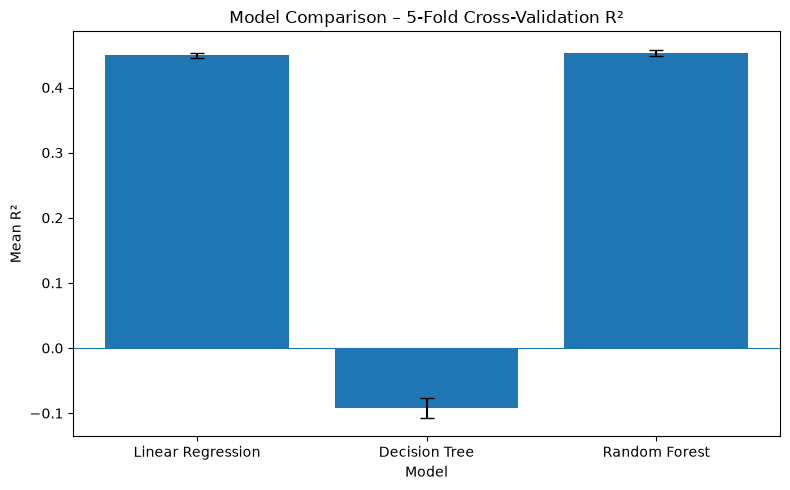

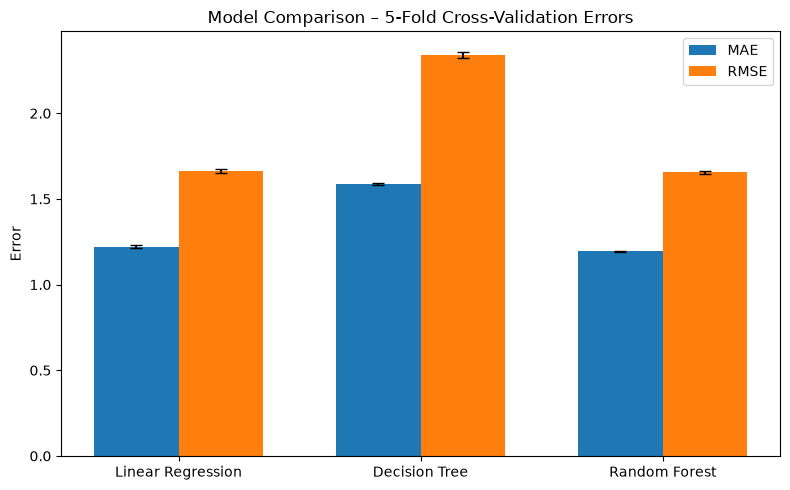

Both CV comparison visualizations saved successfully.
Output directory: c:\Users\aiqiu\Documents\Nackademin\ML\wvs_mlproject\outputs\modeling


In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Create output directory
modeling_output_dir = OUTPUT_DIR
os.makedirs(modeling_output_dir, exist_ok=True)

# Define model order
models = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest"
]

# Arrange summary results in the required model order
plot_summary = (
    model_comparison_summary
    .set_index("Model")
    .loc[models]
)

# ==========================================
# 1. Cross-Validation: R² Comparison
# ==========================================

r2_means = plot_summary["R2_mean"].values
r2_stds = plot_summary["R2_std"].values

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    r2_means,
    yerr=r2_stds,
    capsize=5
)

plt.title("Model Comparison – 5-Fold Cross-Validation R²")
plt.ylabel("Mean R²")
plt.xlabel("Model")
plt.axhline(0, linewidth=0.8)

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Model_CV_R2_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 2. Cross-Validation: Prediction Errors
# ==========================================

mae_means = plot_summary["MAE_mean"].values
mae_stds = plot_summary["MAE_std"].values

rmse_means = plot_summary["RMSE_mean"].values
rmse_stds = plot_summary["RMSE_std"].values

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    mae_means,
    width,
    yerr=mae_stds,
    capsize=4,
    label="MAE"
)

plt.bar(
    x + width / 2,
    rmse_means,
    width,
    yerr=rmse_stds,
    capsize=4,
    label="RMSE"
)

plt.xticks(x, models)
plt.ylabel("Error")
plt.title("Model Comparison – 5-Fold Cross-Validation Errors")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Model_CV_Error_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both CV comparison visualizations saved successfully.")
print("Output directory:", modeling_output_dir)

### Model Comparison – 5-Fold Cross-Validation

All three models were evaluated under the same conditions:
- Hierarchical imputation.
- Top 30 features selected within each training fold.
- Country included using one-hot encoding.
- Identical 5-fold cross-validation splits.
 
| Model | R² Mean ± Std | MAE Mean ± Std | RMSE Mean ± Std |
|---|---:|---:|---:|
| Linear Regression | 0.4497 ± 0.0039 | 1.2219 ± 0.0066 | 1.6624 ± 0.0138 |
| Decision Tree | -0.0915 ± 0.0153 | 1.5854 ± 0.0063 | 2.3412 ± 0.0190 |
| **Random Forest** | **0.4533 ± 0.0047** | **1.1934 ± 0.0046** | **1.6569 ± 0.0086** |

**Key findings:**

- **Random Forest achieved the best overall performance**, with the highest mean R² (0.4533) and the lowest MAE (1.1934) and RMSE (1.6569).
- **Linear Regression performed similarly**, with a mean R² of 0.4497. This suggests that a substantial part of the predictive relationships can be captured by a linear model.
- **Decision Tree performed considerably worse**, with a negative mean R² (-0.0915), indicating poor generalisation to the validation folds.
- Random Forest showed relatively consistent performance across folds, with low standard deviations.

**Conclusion:**

Random Forest achieved the best overall cross-validation performance, although its predictive performance was only marginally better than Linear Regression.
The final model will be evaluated on the held-out test set using R², MAE and RMSE.

In [34]:
import inspect

print(inspect.getsource(prepare_model_data))

def prepare_model_data(
    X_train,
    X_val,
    selected_features
):
    """
    Prepare training and validation data for Random Forest.
    Country is one-hot encoded.
    """

    model_features = selected_features + ["Country"]

    X_train_model = X_train[model_features].copy()
    X_val_model = X_val[model_features].copy()

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

    train_country = encoder.fit_transform(
        X_train_model[["Country"]]
    )

    val_country = encoder.transform(
        X_val_model[["Country"]]
    )

    train_numeric = X_train_model[selected_features].to_numpy()
    val_numeric = X_val_model[selected_features].to_numpy()

    X_train_prepared = np.hstack([
        train_numeric,
        train_country
    ])

    X_val_prepared = np.hstack([
        val_numeric,
        val_country
    ])

    return X_train_prepared, X_val_prepared



## Final Model Training

Based on the 5-fold cross-validation results, Random Forest was selected as the preferred model.

The final model uses:
- Hierarchical imputation.
- Top 30 selected features.
- Country encoded using One-Hot Encoding.
- 200 trees with a fixed random state.

In [35]:
# 1. Fit hierarchical imputer on the full training set
final_imputation_stats = fit_hierarchical_imputer(
    X_train,
    imputation_feature_info
)

# 2. Apply imputation to training and test sets
X_train_final = apply_hierarchical_imputer(
    X_train,
    final_imputation_stats,
    imputation_feature_info
)

X_test_final = apply_hierarchical_imputer(
    X_test,
    final_imputation_stats,
    imputation_feature_info
)

print("Training shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

print("Missing values in training:", X_train_final.isna().sum().sum())
print("Missing values in test:", X_test_final.isna().sum().sum())

Training shape: (77360, 242)
Test shape: (19340, 242)
Missing values in training: 0
Missing values in test: 0


In [36]:
# Select the final Top 30 features using the full training set

final_selected_features, final_feature_ranking = select_top_features(
    X_train_final,
    y_train,
    candidate_features,
    top_k=30
)

print("Number of selected features:", len(final_selected_features))
print("Selected features:")
print(final_selected_features)

Number of selected features: 30
Selected features:
['Q50', 'Q48', 'Q47', 'Q251', 'Q54', 'Q288', 'Q53', 'Q51', 'Q159', 'Q131', 'Q250', 'Q252', 'Q163', 'Q55', 'Q158', 'Q286', 'Q287', 'Q75', 'Q52', 'Q253', 'Q249', 'Q106', 'Q80', 'Q58', 'Q137', 'Q138', 'Q189', 'Q45', 'Q164', 'Q88']


In [37]:
# Prepare final model input
X_train_prepared, X_test_prepared = prepare_model_data(
    X_train_final,
    X_test_final,
    final_selected_features
)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (77360, 96)
Prepared test shape: (19340, 96)


In [38]:
# Initialize the final Random Forest model
final_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train on the full training set
final_model.fit(
    X_train_prepared,
    y_train
)

print("Final Random Forest model trained successfully.")

Final Random Forest model trained successfully.


In [39]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Generate predictions on the test set
y_test_pred = final_model.predict(X_test_prepared)

# Calculate evaluation metrics
final_test_r2 = r2_score(y_test, y_test_pred)
final_test_mae = mean_absolute_error(y_test, y_test_pred)
final_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)
# Save final test evaluation results

final_test_results_df = pd.DataFrame([{
    "Model": "Random Forest",
    "Imputation": "Hierarchical",
    "Features": 30,
    "R2": final_test_r2,
    "MAE": final_test_mae,
    "RMSE": final_test_rmse
}])

final_test_results_df.to_csv(
    OUTPUT_DIR / "WVS_Final_Model_Test_Results.csv",
    index=False
)

print("Final model evaluation results saved.")

# Display results
print("Final Test Set Performance")
print("---------------------------")
print(f"R²:   {final_test_r2:.4f}")
print(f"MAE:  {final_test_mae:.4f}")
print(f"RMSE: {final_test_rmse:.4f}")

Final model evaluation results saved.
Final Test Set Performance
---------------------------
R²:   0.4576
MAE:  1.1793
RMSE: 1.6431


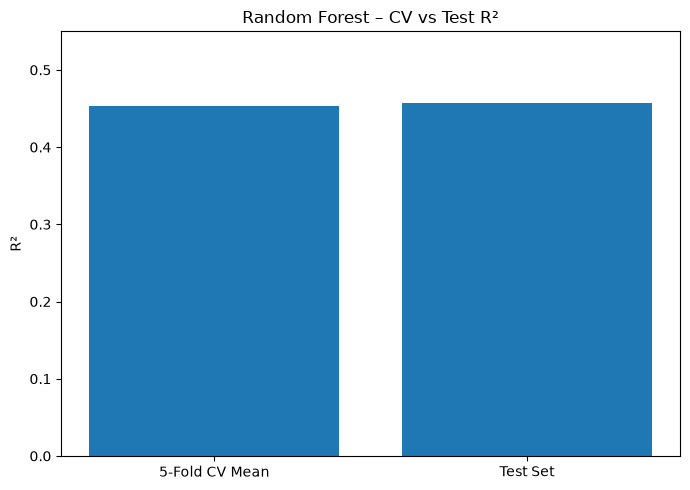

In [40]:
# Random Forest: CV vs Test R²

rf_cv = model_comparison_summary.loc[
    model_comparison_summary["Model"] == "Random Forest"
].iloc[0]

evaluation_sets = ["5-Fold CV Mean", "Test Set"]

r2_values = [
    rf_cv["R2_mean"],
    final_test_r2
]

plt.figure(figsize=(7, 5))

plt.bar(evaluation_sets, r2_values)

plt.ylabel("R²")
plt.title("Random Forest – CV vs Test R²")
plt.ylim(0, 0.55)

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Random_Forest_CV_vs_Test_R2.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

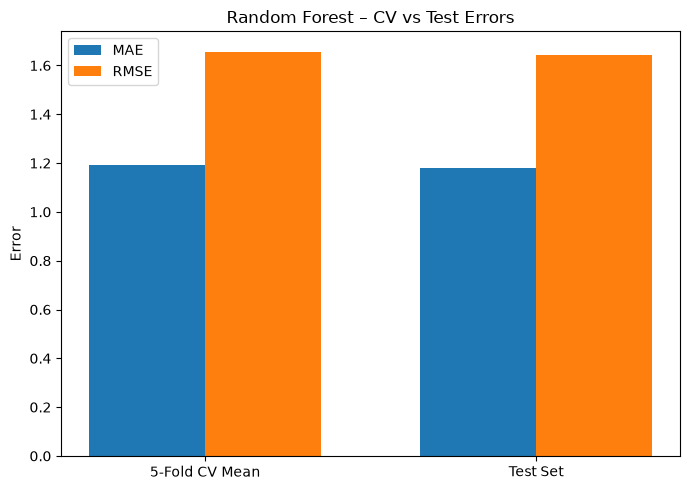

In [41]:
# Random Forest: CV vs Test Errors

mae_values = [
    rf_cv["MAE_mean"],
    final_test_mae
]

rmse_values = [
    rf_cv["RMSE_mean"],
    final_test_rmse
]

x = np.arange(len(evaluation_sets))
width = 0.35

plt.figure(figsize=(7, 5))

plt.bar(
    x - width / 2,
    mae_values,
    width,
    label="MAE"
)

plt.bar(
    x + width / 2,
    rmse_values,
    width,
    label="RMSE"
)

plt.xticks(x, evaluation_sets)
plt.ylabel("Error")
plt.title("Random Forest – CV vs Test Errors")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Random_Forest_CV_vs_Test_Error.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Final Model Evaluation

The selected Random Forest model was trained on the full training set and evaluated on the held-out test set.

**Test Set Performance:**

| Metric | 5-Fold CV Mean | Test Set |
|---|---:|---:|
| R² | 0.4533 | **0.4576** |
| MAE | 1.1934 | **1.1793** |
| RMSE | 1.6569 | **1.6431** |

**Key findings:**
- The model achieved an R² of 0.4576, explaining approximately 45.76% of the variation in life satisfaction in the test set.
- The test MAE was 1.1793, meaning that predictions differed from observed life satisfaction scores by approximately 1.18 points on average.
- Both MAE and RMSE were slightly lower on the test set than the cross-validation averages.
- The similar CV and test results suggest consistent predictive performance, with no obvious indication of substantial overfitting based on these metrics.

**Conclusion:**

Random Forest with hierarchical imputation and the Top 30 selected features was the best-performing configuration among the three evaluated algorithms.

The model demonstrates moderate predictive ability, while a substantial proportion of variation in life satisfaction remains unexplained.

**Evaluation limitation:** The test set was previously used in earlier model comparisons. Therefore, the cross-validation results are used as the primary basis for model selection, while the test-set results are reported as a supplementary evaluation.

### Feature Importance – Understanding the Model

In [42]:
# ==========================================
# 1. Get feature names
# ==========================================

# Recreate the Country encoder
country_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

country_encoder.fit(X_train_final[["Country"]])

country_feature_names = [
    f"Country_{country}"
    for country in country_encoder.categories_[0]
]

# Combine survey features and country columns
all_feature_names = (
    final_selected_features + country_feature_names
)

assert len(all_feature_names) == X_train_prepared.shape[1]
assert len(all_feature_names) == X_test_prepared.shape[1]

assert len(all_feature_names) == len(final_model.feature_importances_)

print("Feature names match the prepared model data.")

# Check dimensions
print("Number of feature names:", len(all_feature_names))
print("Number of model importances:", len(final_model.feature_importances_))


# ==========================================
# 2. Extract Random Forest importance
# ==========================================

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": final_model.feature_importances_
})

# Identify Country features
feature_importance_df["Category"] = np.where(
    feature_importance_df["Feature"].str.startswith("Country_"),
    "Country",
    "Survey Feature"
)

# Aggregate all Country dummy variables
country_importance = feature_importance_df.loc[
    feature_importance_df["Category"] == "Country",
    "Importance"
].sum()

survey_importance = feature_importance_df.loc[
    feature_importance_df["Category"] == "Survey Feature",
    "Importance"
].sum()

# Create aggregated importance table
aggregated_importance = pd.concat([
    feature_importance_df.loc[
        feature_importance_df["Category"] == "Survey Feature",
        ["Feature", "Importance"]
    ],
    pd.DataFrame({
        "Feature": ["Country"],
        "Importance": [country_importance]
    })
], ignore_index=True)

aggregated_importance = aggregated_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

aggregated_importance["Importance_Percent"] = (
    aggregated_importance["Importance"] * 100
)

print(
    "Total aggregated importance:",
    aggregated_importance["Importance"].sum()
)

assert np.isclose(
    aggregated_importance["Importance"].sum(),
    1.0
)
# Save final model feature importance

aggregated_importance.to_csv(
    OUTPUT_DIR / "WVS_Final_Feature_Importance.csv",
    index=False
)

print("Final feature importance saved.")

print("Total importance:", aggregated_importance["Importance"].sum())

aggregated_importance.head(20)

Feature names match the prepared model data.
Number of feature names: 96
Number of model importances: 96
Total aggregated importance: 1.0
Final feature importance saved.
Total importance: 1.0


,Feature,Importance,Importance_Percent
0,Q50,0.296984,29.698356
1,Country,0.131549,13.154918
2,Q48,0.114287,11.428713
3,Q47,0.026896,2.689640
4,Q251,0.025593,2.559272
5,Q252,0.025526,2.552578
6,Q288,0.024952,2.495225
7,Q163,0.024432,2.443178
8,Q106,0.023726,2.372557
9,Q158,0.021094,2.109358


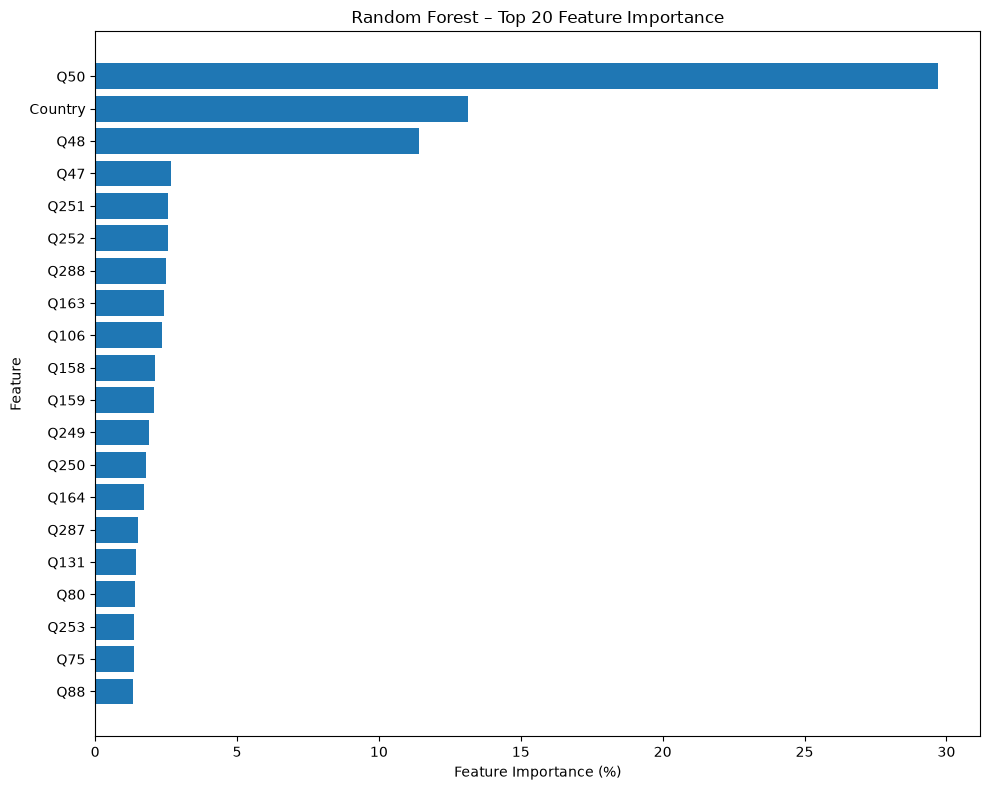

In [43]:
# Select top 20 features
top20_importance = aggregated_importance.head(20).sort_values(
    "Importance_Percent",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20_importance["Feature"],
    top20_importance["Importance_Percent"]
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Random Forest – Top 20 Feature Importance")

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Random_Forest_Top20_Feature_Importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Random Forest – Feature Importance

The feature importance analysis identifies which variables contribute most to the Random Forest model's predictive performance.

**Key findings:**

- Q50 (household financial satisfaction) is the most important feature, accounting for approximately 29.70% of total importance.
- Country ranks second, contributing 13.15%, suggesting that national context contains substantial predictive information.
- Q48 (perceived freedom of choice and control) ranks third, with an importance of 11.43%.
- Together, Q50, Country and Q48 account for approximately 54.28% of total feature importance.
- Other relevant predictors include self-rated health (Q47), political attitudes (Q251 and Q252), relative household income (Q288), and attitudes towards science and technology (Q158, Q159 and Q163).

**Conclusion:**

The results suggest that life satisfaction can be predicted using a combination of economic, personal, political and national-context factors. Household financial satisfaction is particularly prominent, while perceived personal control and country-level context also contribute substantially.

**Methodological limitation:**

These results are based on impurity-based Random Forest importance. Importance values indicate predictive contribution within the fitted model, but do not show whether a variable has a positive or negative relationship with life satisfaction. They should not be interpreted as causal effects.

| Q-code | Questionnaire question |
|---|---|
| Q50 | How satisfied are you with the financial situation of your household? |
| Q48 | How much freedom of choice and control do you feel you have over the way your life turns out? |
| Q47 | Self-rated health. |

### Permutation Feature Importance

In [44]:
# ==========================================
# Permutation Feature Importance
# ==========================================

from sklearn.metrics import r2_score

# Baseline test performance
baseline_r2 = r2_score(
    y_test,
    final_model.predict(X_test_prepared)
)

print(f"Baseline Test R²: {baseline_r2:.4f}")


# Identify feature column positions
survey_feature_indices = {
    feature: all_feature_names.index(feature)
    for feature in final_selected_features
}

country_indices = [
    i for i, name in enumerate(all_feature_names)
    if name.startswith("Country_")
]


# Permutation settings
n_repeats = 10
rng = np.random.default_rng(42)

permutation_results = []


# 1. Permute each survey feature individually
for feature, column_idx in survey_feature_indices.items():

    importance_scores = []

    for repeat in range(n_repeats):

        X_permuted = X_test_prepared.copy()

        permutation = rng.permutation(len(X_permuted))

        X_permuted[:, column_idx] = (
            X_test_prepared[permutation, column_idx]
        )

        permuted_r2 = r2_score(
            y_test,
            final_model.predict(X_permuted)
        )

        importance_scores.append(
            baseline_r2 - permuted_r2
        )

    permutation_results.append({
        "Feature": feature,
        "Importance_Mean": np.mean(importance_scores),
        "Importance_Std": np.std(importance_scores, ddof=1)
    })


# 2. Permute all Country columns together
country_scores = []

for repeat in range(n_repeats):

    X_permuted = X_test_prepared.copy()

    permutation = rng.permutation(len(X_permuted))

    X_permuted[:, country_indices] = (
        X_test_prepared[permutation][:, country_indices]
    )

    permuted_r2 = r2_score(
        y_test,
        final_model.predict(X_permuted)
    )

    country_scores.append(
        baseline_r2 - permuted_r2
    )


permutation_results.append({
    "Feature": "Country",
    "Importance_Mean": np.mean(country_scores),
    "Importance_Std": np.std(country_scores, ddof=1)
})


# Create result DataFrame
permutation_importance_df = pd.DataFrame(
    permutation_results
)

permutation_importance_df = permutation_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\nPermutation Importance Results:")
display(permutation_importance_df.head(20))

permutation_importance_df.to_csv(
    OUTPUT_DIR / "WVS_Final_Permutation_Importance.csv",
    index=False
)

print("Permutation importance saved.")

Baseline Test R²: 0.4576

Permutation Importance Results:


,Feature,Importance_Mean,Importance_Std
0,Q50,0.351895,0.006067
1,Q48,0.139913,0.003123
2,Country,0.048798,0.002637
3,Q47,0.032300,0.001576
4,Q164,0.008858,0.000589
5,Q252,0.004978,0.000736
6,Q131,0.003788,0.000515
7,Q163,0.003357,0.000496
8,Q159,0.003047,0.000695
9,Q158,0.002463,0.000449


Permutation importance saved.


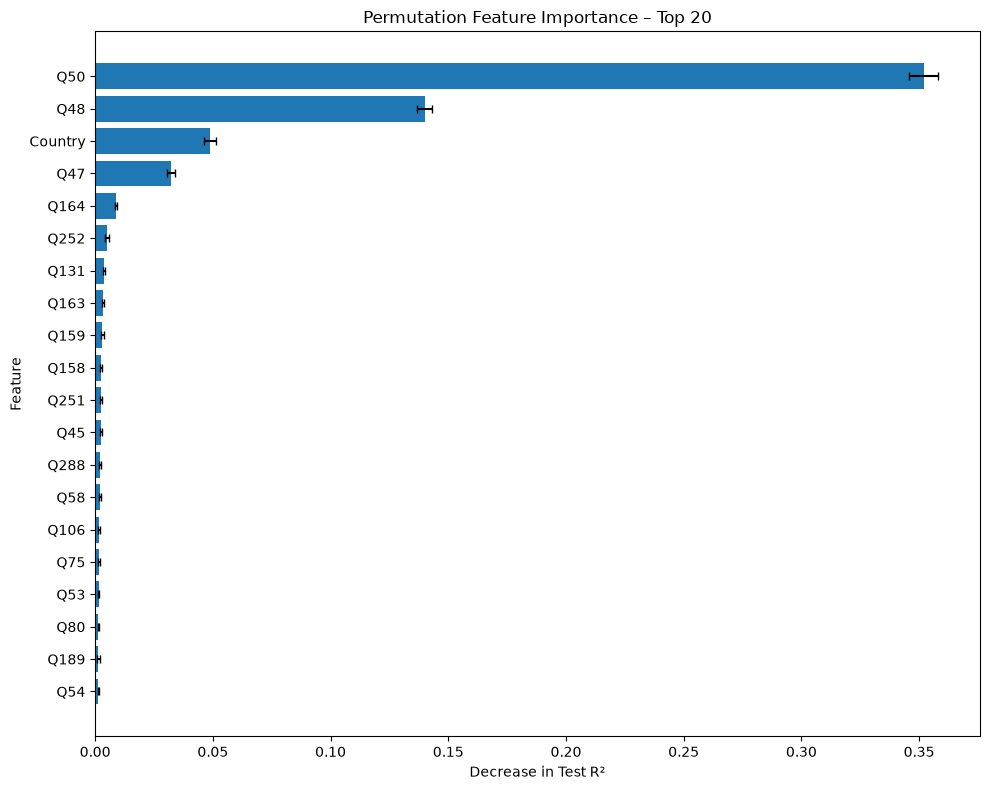

In [45]:
# ==========================================
# Permutation Importance – Top 20
# ==========================================

top20_permutation = (
    permutation_importance_df
    .head(20)
    .sort_values("Importance_Mean", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20_permutation["Feature"],
    top20_permutation["Importance_Mean"],
    xerr=top20_permutation["Importance_Std"],
    capsize=3
)

plt.xlabel("Decrease in Test R²")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance – Top 20")

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Permutation_Importance_Top20.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

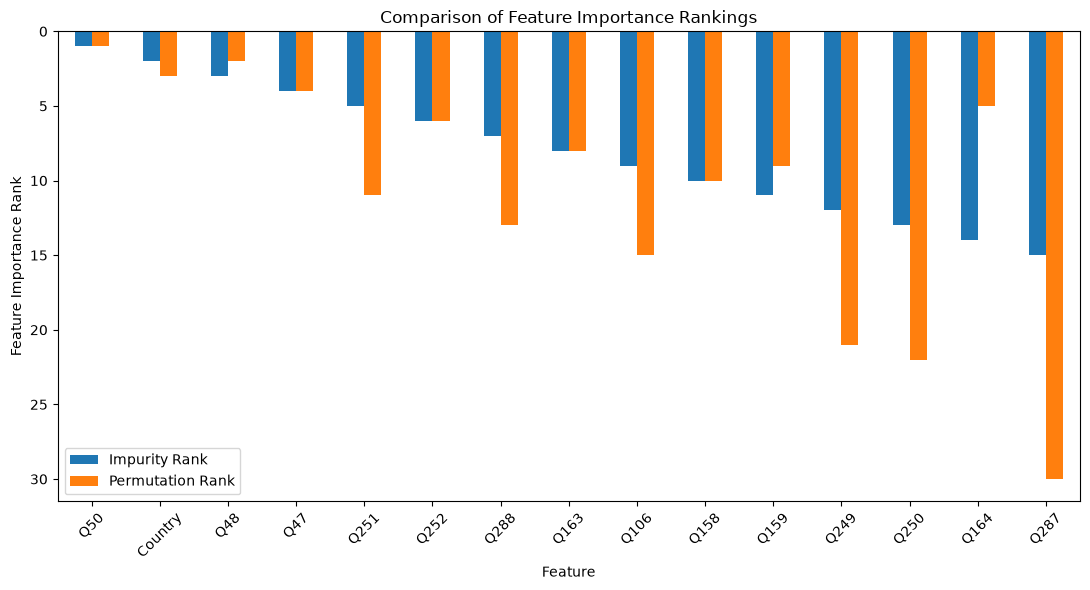

In [46]:
# ==========================================
# Compare Two Feature Importance Methods
# ==========================================

impurity_rank = (
    aggregated_importance
    .set_index("Feature")["Importance"]
    .rank(ascending=False, method="min")
)

permutation_rank = (
    permutation_importance_df
    .set_index("Feature")["Importance_Mean"]
    .rank(ascending=False, method="min")
)

rank_comparison = pd.DataFrame({
    "Impurity Rank": impurity_rank,
    "Permutation Rank": permutation_rank
}).dropna()

rank_comparison = rank_comparison.sort_values(
    "Impurity Rank"
).head(15)

rank_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel("Feature Importance Rank")
plt.xlabel("Feature")
plt.title("Comparison of Feature Importance Rankings")
plt.xticks(rotation=45)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Feature_Importance_Rank_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Permutation Feature Importance

Permutation importance was calculated using the final Random Forest model and the test dataset. Each feature was shuffled independently across 10 repetitions, while all Country one-hot encoded columns were shuffled together.

**Key findings:**

- Q50 (household financial satisfaction) is the most influential predictor. Shuffling this feature reduces the model's R² by approximately 0.352.
- Q48 (freedom of choice and control) ranks second, with an average R² decrease of approximately 0.140.
- Country ranks third, confirming the predictive relevance of national context.
- Q47 (self-rated health) also makes a notable contribution.
- Q164 (importance of God) ranks considerably higher in permutation importance than in impurity-based importance.
- Most remaining features have relatively small individual contributions.

**Comparison with impurity-based importance:**

Both methods consistently identify Q50, Q48, Country and Q47 among the most important predictors. However, some differences in ranking are observed, particularly for Q164. This highlights the value of using multiple feature importance methods when interpreting model predictions.

**Conclusion:**

The results reinforce the importance of household financial satisfaction, perceived personal freedom and control, health, and national context in predicting life satisfaction.

Permutation importance measures the model's dependence on individual features, rather than causal effects. Its values can also be influenced by correlations and overlapping information between predictors.

| Q-code | Questionnaire topic |
|---|---|
| Q50 | Satisfaction with household financial situation |
| Q48 | Freedom of choice and control over one's life |
| Q47 | Self-rated health |
| Q164 | Importance of God in one's life |
| Q288 | Relative household income position |
| Q251 / Q252 | Political and democracy-related perceptions |
| Q158 / Q159 / Q163 | Attitudes towards science and technology |

In [47]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [48]:
# Select 500 test observations for SHAP analysis
rng = np.random.default_rng(42)

shap_sample_indices = rng.choice(
    len(X_test_prepared),
    size=500,
    replace=False
)

X_shap_sample = X_test_prepared[
    shap_sample_indices
]

print("SHAP sample shape:", X_shap_sample.shape)

SHAP sample shape: (500, 96)


In [49]:
# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_shap_sample
)

print("SHAP values shape:", np.array(shap_values).shape)

SHAP values shape: (500, 96)


In [50]:
# Convert SHAP values to numpy array
shap_values_array = np.asarray(shap_values)

# Identify Country feature positions
country_indices = [
    i for i, name in enumerate(all_feature_names)
    if name.startswith("Country_")
]

# Survey feature SHAP values
survey_shap_values = shap_values_array[
    :, :len(final_selected_features)
]

# Aggregate Country SHAP values for each respondent
country_shap_values = shap_values_array[
    :, country_indices
].sum(axis=1)

# Combine survey features and aggregated Country
grouped_shap_values = np.column_stack([
    survey_shap_values,
    country_shap_values
])

# Grouped feature names
grouped_feature_names = (
    final_selected_features + ["Country"]
)

# Validate dimensions
assert grouped_shap_values.shape[1] == len(
    grouped_feature_names
)

assert grouped_shap_values.shape[0] == len(
    X_shap_sample
)

print("Grouped SHAP values validated.")
print("Grouped SHAP shape:", grouped_shap_values.shape)

Grouped SHAP values validated.
Grouped SHAP shape: (500, 31)


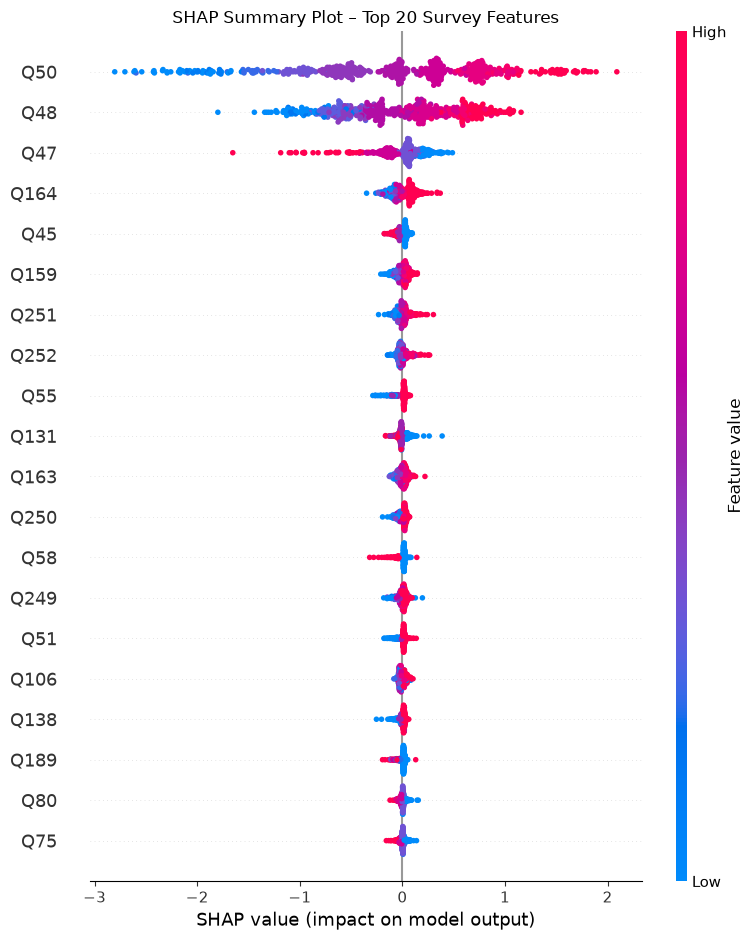

In [51]:
# Create DataFrame for the 30 survey features
X_shap_survey = pd.DataFrame(
    X_shap_sample[:, :len(final_selected_features)],
    columns=final_selected_features
)

shap.summary_plot(
    survey_shap_values,
    X_shap_survey,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot – Top 20 Survey Features")
plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_SHAP_Summary_Top20.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

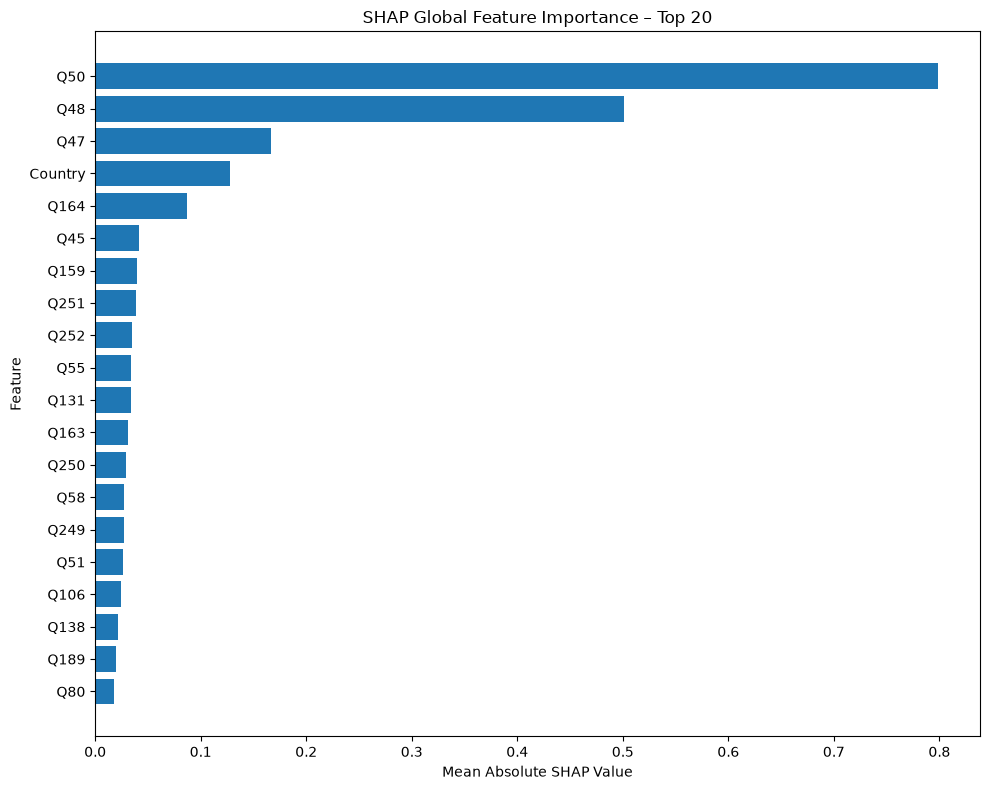

SHAP importance saved.


,Feature,Mean_Abs_SHAP
0,Q50,0.798553
1,Q48,0.500693
2,Q47,0.166802
3,Country,0.127559
4,Q164,0.087127
5,Q45,0.041181
6,Q159,0.039875
7,Q251,0.038900
8,Q252,0.034775
9,Q55,0.034156


In [52]:
# Calculate mean absolute SHAP values
grouped_shap_importance = pd.DataFrame({
    "Feature": grouped_feature_names,
    "Mean_Abs_SHAP": np.abs(grouped_shap_values).mean(axis=0)
})

grouped_shap_importance = grouped_shap_importance.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

# Plot Top 20
top20_shap = grouped_shap_importance.head(20).sort_values(
    "Mean_Abs_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20_shap["Feature"],
    top20_shap["Mean_Abs_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Global Feature Importance – Top 20")

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_SHAP_Global_Importance_Top20.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

grouped_shap_importance.to_csv(
    OUTPUT_DIR / "WVS_Final_SHAP_Importance.csv",
    index=False
)

print("SHAP importance saved.")

display(grouped_shap_importance.head(20))

### Psychological Interpretation of Key Predictors

The SHAP analysis highlights the importance of household financial satisfaction (Q50), perceived freedom and control (Q48), self-rated health (Q47), and the importance of God in one's life (Q164).

**Q164 – Importance of God**

Q164 ranks substantially higher in SHAP and permutation importance than in impurity-based importance. This suggests that religious importance contains predictive information that may not be fully reflected by tree-splitting importance.

From a psychological perspective, religious importance may capture aspects of personal values, meaning, coping resources or social belonging. However, Q164 directly measures the perceived importance of God, rather than these underlying mechanisms. Therefore, these explanations should be treated as theoretical interpretations rather than empirically established pathways.

**Q50 – Financial Satisfaction vs. Q288 – Relative Income Position**

Q50 measures subjective satisfaction with the household's financial situation, whereas Q288 measures the household's position within the national income scale.

The substantially higher importance of Q50 suggests that subjective financial evaluation provides more predictive information than relative income position alone.

Financial satisfaction may reflect not only income, but also perceived financial adequacy, economic stress, expectations, social comparison and perceived control over household finances. Individuals with similar income positions may therefore report different levels of financial satisfaction.

**Relationship with Life Satisfaction (Q49)**

Q50 is conceptually related to the target variable Q49, which measures overall life satisfaction. Financial satisfaction may represent an important domain of individuals' broader evaluations of their lives.

Consequently, the high predictive importance of Q50 may partly reflect this conceptual proximity, in addition to the relevance of economic conditions.

**Conclusion**

The results suggest that subjective evaluations of financial circumstances may be more informative for predicting life satisfaction than relative income position alone. They also highlight the potential relevance of personal values and perceived control.

These findings describe predictive relationships and do not establish causal effects.

**Relevant WVS Questions**
- Q49: All things considered, how satisfied are you with your life as a whole these days?
- Q50: How satisfied are you with the financial situation of your household?
- Q288: On this card is an income scale on which 1 indicates the lowest income group and 10 the highest income group in your country. We would like to know in what group your household is.
- Q164: How important is God in your life?

### Subjective Financial Satisfaction vs. Relative Income Position

This analysis examines the relationship between household financial satisfaction (Q50) and relative household income position (Q288).

Q50 measures respondents' subjective satisfaction with their household's financial situation, whereas Q288 represents their perceived position within the national income distribution.

The analysis focuses on three questions:

- How strongly are relative income position and financial satisfaction associated?
- Does average financial satisfaction increase across income positions?
- Does relative income position provide additional predictive information in the model beyond financial satisfaction?

The SHAP dependence plot is used to explore how Q50 contributes to model predictions across different values of Q288.

This analysis helps distinguish subjective financial evaluation from relative economic position. Any observed patterns are interpreted as associations and model-based relationships, rather than causal effects.

In [53]:
# ==========================================
# Q50 vs Q288: Spearman Correlation
# ==========================================

from scipy.stats import spearmanr

q50 = X_train_final["Q50"]
q288 = X_train_final["Q288"]

correlation, p_value = spearmanr(q50, q288)

print(f"Spearman correlation: {correlation:.4f}")
print(f"P-value: {p_value:.4e}")

Spearman correlation: 0.3334
P-value: 0.0000e+00


In [54]:
# ==========================================
# Average Financial Satisfaction by Income Position
# ==========================================

q50_q288_summary = (
    X_train_final
    .groupby("Q288")["Q50"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

q50_q288_summary.columns = [
    "Q288_Income_Position",
    "Mean_Q50",
    "Median_Q50",
    "Count"
]

display(q50_q288_summary)

,Q288_Income_Position,Mean_Q50,Median_Q50,Count
0,1.0,4.841194,5.0,5831
1,2.0,4.981584,5.0,4344
2,3.0,5.315297,5.0,8446
3,4.0,5.742732,6.0,10767
4,5.0,6.301130,6.0,19470
5,6.0,6.654845,7.0,12012
6,7.0,7.086521,7.0,8784
7,8.0,7.488764,8.0,4628
8,9.0,7.702142,8.0,1447
9,10.0,8.081545,9.0,1631


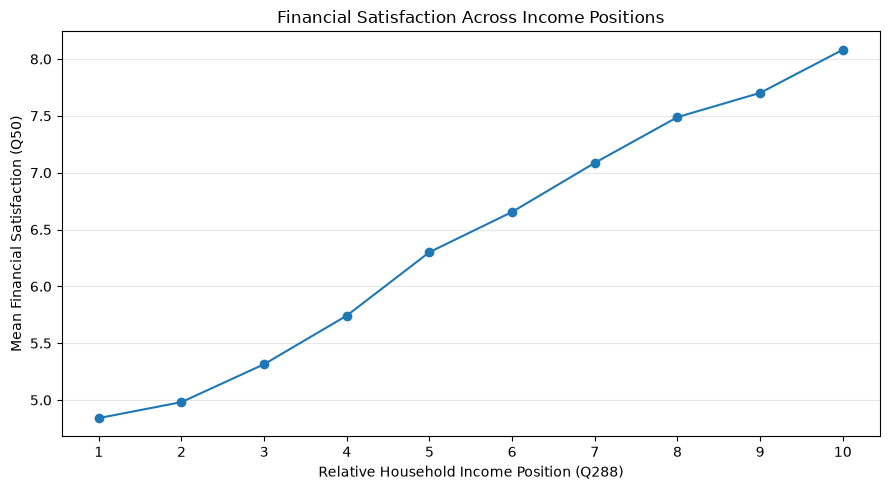

In [55]:
# ==========================================
# Plot Q288 vs Mean Q50
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    q50_q288_summary["Q288_Income_Position"],
    q50_q288_summary["Mean_Q50"],
    marker="o"
)

plt.xlabel("Relative Household Income Position (Q288)")
plt.ylabel("Mean Financial Satisfaction (Q50)")
plt.title("Financial Satisfaction Across Income Positions")

plt.xticks(range(1, 11))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Q50_by_Q288_Income_Position.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

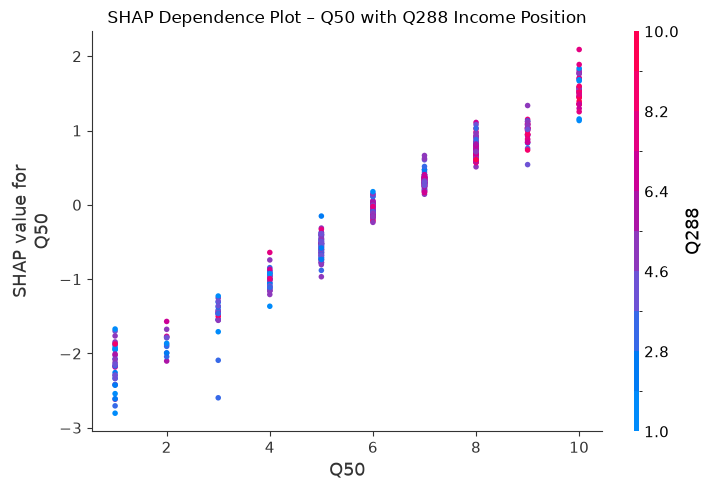

In [56]:
# ==========================================
# SHAP Dependence Plot
# Q50 colored by Q288
# ==========================================

plt.figure()

shap.dependence_plot(
    "Q50",
    survey_shap_values,
    X_shap_survey,
    interaction_index="Q288",
    show=False
)

plt.title(
    "SHAP Dependence Plot – Q50 "
    "with Q288 Income Position"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_SHAP_Q50_by_Q288.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Resources, Needs and Subjective Financial Well-being

The results raise an important question about the relationship between economic resources and life satisfaction.

Relative household income position (Q288) is positively associated with household financial satisfaction (Q50). However, Q50 provides substantially stronger predictive information for overall life satisfaction than Q288.

This suggests that economic position and subjective financial evaluation are related but distinct dimensions of well-being.

From a psychological and philosophical perspective, financial satisfaction may reflect the perceived adequacy of resources in relation to personal needs, expectations and life goals. Individuals with similar economic positions may therefore evaluate their financial circumstances differently.

The findings are consistent with the idea that well-being may depend not only on the amount of resources available, but also on how those resources relate to an individual's perceived needs and aspirations.

However, the present data do not directly measure material needs or income aspirations. Therefore, the relationship between resources, perceived adequacy and life satisfaction should be treated as a theoretical interpretation rather than a tested causal mechanism.

The results highlight the distinction between economic resources and the subjective experience of economic well-being.

In [57]:
# ==========================================
# Q50 SHAP by Relative Income Position
# ==========================================

# Create analysis DataFrame from SHAP sample
q50_shap_analysis = X_shap_survey[
    ["Q50", "Q288"]
].copy()

q50_shap_analysis["Q50_SHAP"] = (
    survey_shap_values[
        :,
        final_selected_features.index("Q50")
    ]
)

# Group relative income position
q50_shap_analysis["Income_Group"] = pd.cut(
    q50_shap_analysis["Q288"],
    bins=[0, 3, 7, 10],
    labels=[
        "Lower (1-3)",
        "Middle (4-7)",
        "Higher (8-10)"
    ]
)

# Summarize mean SHAP by Q50 and income group
q50_group_summary = (
    q50_shap_analysis
    .groupby(
        ["Income_Group", "Q50"],
        observed=True
    )
    .agg(
        Mean_SHAP=("Q50_SHAP", "mean"),
        Count=("Q50_SHAP", "size")
    )
    .reset_index()
)

display(q50_group_summary)

,Income_Group,Q50,Mean_SHAP,Count
0,Lower (1-3),1.0,-2.247156,15
1,Lower (1-3),2.0,-1.916368,5
2,Lower (1-3),3.0,-1.615815,11
3,Lower (1-3),4.0,-1.027632,12
4,Lower (1-3),5.0,-0.559341,29
5,Lower (1-3),6.0,-0.027682,13
6,Lower (1-3),7.0,0.360159,13
7,Lower (1-3),8.0,0.785253,11
8,Lower (1-3),9.0,0.992013,3
9,Lower (1-3),10.0,1.510222,7


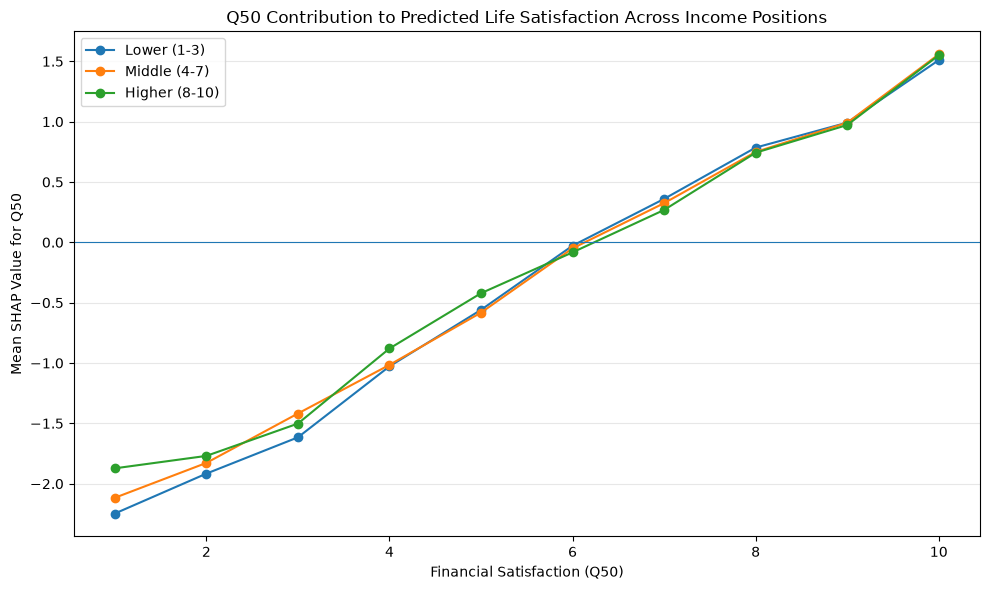

In [58]:
# ==========================================
# Plot Q50 SHAP by Income Group
# ==========================================

plt.figure(figsize=(10, 6))

for group in q50_group_summary["Income_Group"].unique():

    group_data = q50_group_summary[
        q50_group_summary["Income_Group"] == group
    ]

    plt.plot(
        group_data["Q50"],
        group_data["Mean_SHAP"],
        marker="o",
        label=group
    )

plt.axhline(0, linewidth=0.8)

plt.xlabel("Financial Satisfaction (Q50)")
plt.ylabel("Mean SHAP Value for Q50")

plt.title(
    "Q50 Contribution to Predicted Life Satisfaction "
    "Across Income Positions"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        modeling_output_dir,
        "WVS_Q50_SHAP_by_Income_Group.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Q50 SHAP Contributions Across Relative Income Groups

The SHAP analysis examined whether the contribution of household financial satisfaction (Q50) to predicted life satisfaction differs across relative household income positions (Q288).

Respondents were grouped into three categories:

- Lower income position: Q288 = 1–3
- Middle income position: Q288 = 4–7
- Higher income position: Q288 = 8–10

The results show a broadly similar increasing pattern across all three groups. Low Q50 values generally correspond to negative SHAP contributions, whereas high Q50 values correspond to positive contributions.

The three curves follow similar trajectories, suggesting that the relationship between subjective financial satisfaction and model predictions is broadly consistent across relative income groups.

No strong visual evidence of a substantial income-group interaction was observed. However, some combinations of Q50 and income group had very small sample sizes, particularly in the higher-income group. Therefore, differences between the curves should be interpreted cautiously.

Overall, the results suggest that subjective financial satisfaction provides predictive information about life satisfaction across different relative income positions. This is consistent with the distinction between economic position and the subjective evaluation of one's financial circumstances.

The findings are exploratory and model-based. They do not establish a causal relationship or directly measure respondents' material needs and expectations.

### Practical Implications: Financial Well-being Beyond Income

The findings suggest that life satisfaction is associated not only with relative economic position, but also with how individuals evaluate their financial circumstances.

Household financial satisfaction (Q50) provides substantially stronger predictive information about life satisfaction than relative household income position (Q288) in the final model.

This finding raises an important practical question: how can individuals improve their perceived financial well-being?

Although the analysis does not identify causal interventions, it provides a basis for several reflective suggestions.

**1. Define personal financial sufficiency**

Individuals may benefit from identifying which material conditions are genuinely important for their needs and preferred way of life, rather than relying entirely on external standards of success.

**2. Strengthen financial security**

Financial planning, manageable expenses and preparation for unexpected costs may help individuals feel more secure about their financial circumstances.

**3. Reflect on social comparison**

Comparing one's financial position with others may influence how economic circumstances are evaluated. Focusing on personal goals and needs may provide a more meaningful basis for financial evaluation.

**4. Align spending with personal values**

Reflecting on whether spending supports important life goals may help individuals evaluate their financial circumstances beyond the amount of money they possess.

**5. Recognize broader sources of well-being**

Financial circumstances are important, but life satisfaction also relates to social relationships, health, personal values, security and perceived control over one's life.

These suggestions are informed by the study's findings and broader conceptual considerations. They should not be interpreted as interventions directly tested by the predictive model.

The central message is not that income is unimportant, but that economic resources and subjective financial well-being are distinct dimensions of a satisfying life.

# Final Research Summary

## 1. Research Objective

This project investigates the factors associated with life satisfaction using data from the World Values Survey (WVS) Wave 7.

The research question is:

**To what extent can economic, demographic, social and personal factors explain and predict differences in life satisfaction across countries?**

The project approaches this question from two complementary perspectives:

1. A thematic analysis based on broad questionnaire categories.
2. An individual-feature analysis focusing on specific survey questions.

The aim is to understand both the broader domains associated with life satisfaction and the specific variables that provide the strongest predictive information.

---

## 2. Thematic Questionnaire Analysis

The first analysis explored life satisfaction through broad questionnaire categories.

The thematic categories included:

- Economic
- Demographic & Background
- Social & Community
- Personal Values & Wellbeing
- Political & Institutional
- Science & Technology
- Security

This analysis provided a broad overview of the different areas of life represented in the WVS questionnaire.

Rather than focusing immediately on individual questions, the thematic approach helped identify which domains were relevant to the study of life satisfaction and provided a foundation for the subsequent feature-level analysis.

The thematic analysis and the individual-feature analysis serve complementary purposes. The former provides a broad perspective, while the latter examines the predictive information contained in specific survey variables.

---

## 3. Individual Feature Analysis

The second analysis focused on individual questionnaire variables.

The target variable was Q49, which measures overall life satisfaction on a scale from 1 to 10.

The analysis included:

- Variable classification and data inspection
- Missing-value handling
- Correlation analysis
- Feature selection experiments
- Model comparison
- Feature importance analysis
- SHAP interpretation

The feature selection process was conducted within the cross-validation folds to reduce information leakage.

The final feature experiment compared Top 20 and Top 30 predictors using simple and hierarchical imputation.

The results showed that Top 30 features performed slightly better than Top 20 features. Hierarchical imputation also produced a small improvement over simple imputation, although the difference was limited.

The preferred configuration was therefore hierarchical imputation with Top 30 features.

---

## 4. Model Comparison

Three regression algorithms were compared under the same experimental conditions:

- Linear Regression
- Decision Tree
- Random Forest

The comparison used 5-fold cross-validation, hierarchical imputation, fold-level Top 30 feature selection and one-hot encoding of Country.

Random Forest achieved the strongest overall cross-validation performance.

| Model | R² Mean ± Std | MAE Mean ± Std | RMSE Mean ± Std |
|---|---:|---:|---:|
| Linear Regression | 0.4497 ± 0.0039 | 1.2219 ± 0.0066 | 1.6624 ± 0.0138 |
| Decision Tree | -0.0915 ± 0.0153 | 1.5854 ± 0.0063 | 2.3412 ± 0.0190 |
| Random Forest | 0.4533 ± 0.0047 | 1.1934 ± 0.0046 | 1.6569 ± 0.0086 |

Random Forest achieved the highest mean R² and the lowest mean MAE and RMSE.

The Decision Tree performed substantially worse, indicating that a single decision tree was insufficient to capture the predictive patterns in the data under the tested configuration.

The final Random Forest model was trained using the selected features and hierarchical imputation.

### Final Test Set Performance

| Metric | Result |
|---|---:|
| R² | 0.4576 |
| MAE | 1.1793 |
| RMSE | 1.6431 |

The final model explains approximately 45.8% of the variation in life satisfaction in the test set.

These results indicate moderate predictive performance. The model captures meaningful patterns in life satisfaction, but a substantial proportion of individual variation remains unexplained.

---

## 5. Model Interpretation

Feature importance, permutation importance and SHAP were used to examine the predictive contributions of individual variables.

Across the interpretation methods, Q50 consistently emerged as one of the most important predictors.

Q50 measures satisfaction with the financial situation of the household.

Country also provided important predictive information, suggesting that national context is relevant when predicting life satisfaction.

Other influential variables included Q48, which measures perceived freedom of choice and control over one's life, and Q47, which measures self-rated health.

The interpretation results suggest that life satisfaction is associated with a combination of subjective financial evaluation, perceived personal control, health and national context.

Feature importance reflects predictive contribution within the fitted model. It does not establish causal effects.

---

## 6. Financial Satisfaction and Relative Income Position

A further analysis examined the relationship between household financial satisfaction (Q50) and relative household income position (Q288).

Q288 represents respondents' perceived position within the income distribution of their country. It does not measure absolute household income.

Spearman's rank correlation between Q50 and Q288 was 0.3334, indicating a moderate positive association.

Mean financial satisfaction increased consistently across relative income positions, from approximately 4.84 in the lowest group to 8.08 in the highest group.

The SHAP dependence analysis showed a clear increasing relationship between Q50 and its contribution to predicted life satisfaction.

When respondents were grouped by relative income position, the Q50 SHAP patterns were broadly similar across lower, middle and higher income groups.

This suggests that subjective financial satisfaction provides predictive information across different relative income positions.

However, the analysis does not establish that income is unimportant or that financial satisfaction is a causal mechanism.

---

## 7. Discussion: Beyond Economic Success

The findings highlight a distinction between economic position and subjective financial well-being.

Relative income position is associated with financial satisfaction, but it does not fully explain how individuals evaluate their financial circumstances.

Q50 may reflect a broader subjective assessment of financial life, potentially including perceived adequacy, financial security, expectations and personal priorities.

The results therefore raise an important question:

**Is financial well-being determined only by how much people possess, or also by how they evaluate their resources in relation to their needs and expectations?**

The current data do not directly measure material needs or income aspirations. Therefore, this question should be treated as a theoretical interpretation and a direction for further research.

The central finding is not that income does not matter, but that economic position and subjective financial well-being are distinct dimensions of life satisfaction.

---

## 8. Practical Implications

The findings may encourage reflection on financial well-being beyond income position alone.

Potential areas for personal reflection include:

- Defining what financial sufficiency means in relation to personal needs.
- Strengthening financial security and preparedness.
- Reflecting on social comparison and financial expectations.
- Aligning spending with personal values and life goals.
- Recognizing non-financial sources of well-being, such as relationships, health and personal control.

These suggestions are informed by the study's findings and broader conceptual considerations. They were not directly tested as interventions by the predictive model.

---

## 9. Limitations

Several limitations should be considered.

First, the analysis uses cross-sectional survey data. The results describe associations and predictive relationships rather than causal effects.

Second, the study uses pooled data from multiple countries. Country-level differences may influence individual-level relationships, and the results should not be interpreted as purely within-country effects.

Third, Country was included as a predictor. The model's performance therefore reflects prediction for respondents from countries represented in the training data. It does not demonstrate generalization to entirely unseen countries.

Fourth, the final test set had previously been used in earlier exploratory model comparisons. The final test results should therefore be interpreted with this history in mind.

Finally, the WVS does not directly measure all potentially relevant factors, including individual material needs, income aspirations and the full range of personal circumstances.

---

## 10. Conclusion

This project explored life satisfaction through both broad questionnaire categories and individual survey variables.

The thematic analysis provided a broad perspective on the domains represented in the WVS, while the individual-feature analysis identified specific variables with strong predictive information.

The final Random Forest model achieved moderate predictive performance. Household financial satisfaction (Q50) emerged as one of the strongest predictors, while relative income position (Q288) was positively associated with financial satisfaction but provided less predictive information.

Overall, the findings suggest that life satisfaction is associated with multiple dimensions of life and that economic position alone does not fully capture subjective financial well-being.

The project highlights the importance of examining not only economic resources, but also how individuals evaluate and experience their circumstances.

### Future Analysis: Q164

Investigate why Q164 (importance of God in one's life) ranks
relatively lower in impurity-based feature importance but appears
more prominent in SHAP and permutation importance.

Potential follow-up:
- Examine the distribution of Q164 SHAP values.
- Explore SHAP patterns across Q164 response categories.
- Investigate possible interactions with other predictors.

This analysis is exploratory and not required for the main project conclusions.

## Final Results and Output Files

This section contains the final model evaluation, cross-validation
results, and model interpretation outputs.

The selected final model is:

- Imputation: Hierarchical
- Feature selection: Top 30
- Model: Random Forest

In [59]:
from pathlib import Path

modeling_output_dir = OUTPUT_DIR

print("Final modeling output files:")
print("---------------------------")

for file_path in sorted(modeling_output_dir.glob("*")):
    if file_path.is_file():
        print(file_path.name)

Final modeling output files:
---------------------------
test_r2_across_stages.png
train_test_r2_gap.png
train_vs_test_r2.png
WVS_10Fold_CV_Results.csv
WVS_10Fold_CV_Summary.csv
WVS_Feature_Experiments_CV_Results.csv
WVS_Feature_Experiments_CV_Summary.csv
WVS_Feature_Importance_Rank_Comparison.png
WVS_Final_Feature_Importance.csv
WVS_Final_Model_Test_Results.csv
WVS_Final_Permutation_Importance.csv
WVS_Final_SHAP_Importance.csv
WVS_Final_Top15_Feature_Importance.png
WVS_Final_Top30_Feature_Ranking.csv
WVS_Model_Comparison_CV_Results.csv
WVS_Model_Comparison_CV_Summary.csv
WVS_Model_CV_Error_Comparison.png
WVS_Model_CV_R2_Comparison.png
WVS_Permutation_Importance_Top20.png
WVS_Q50_by_Q288_Income_Position.png
WVS_Q50_SHAP_by_Income_Group.png
WVS_Random_Forest_CV_vs_Test_Error.png
WVS_Random_Forest_CV_vs_Test_R2.png
WVS_Random_Forest_Top20_Feature_Importance.png
WVS_SHAP_Global_Importance_Top20.png
WVS_SHAP_Q50_by_Q288.png
WVS_SHAP_Summary_Top20.png
